# Singular value decomposition applied to images

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider

A grey scale image is a matrix: each entry is the brightness of a pixel. Its singular value decomposition
$$X = UDV^T = \sum_j d_j\,u_jv_j^T$$
writes the image as a sum of matrices of rank one, ordered by importance. Keeping only the first $k$ terms gives the best approximation of rank $k$ of the image (Eckart-Young theorem), and needs much less storage: $k(n+p+1)$ numbers instead of $np$.

In [2]:
img = plt.imread('taguchi.jpg')
img = img/255

n, p = img.shape
print('Size of the image:', n, 'x', p, '=', n*p, 'pixels')

Size of the image: 271 x 232 = 62872 pixels


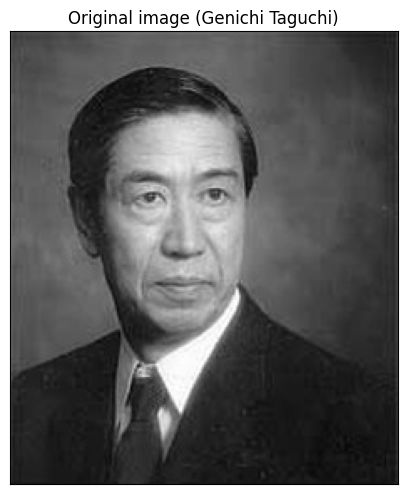

In [3]:
fig, ax = plt.subplots(figsize=(5, 6))
ax.imshow(img, cmap='gray', vmin=0, vmax=1)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('Original image (Genichi Taguchi)');

In [4]:
u, d, v_T  = np.linalg.svd(img, full_matrices=False)

## The singular values

The singular values decrease very fast: a few terms have most of the "energy" $\sum_j d_j^2$ of the image.

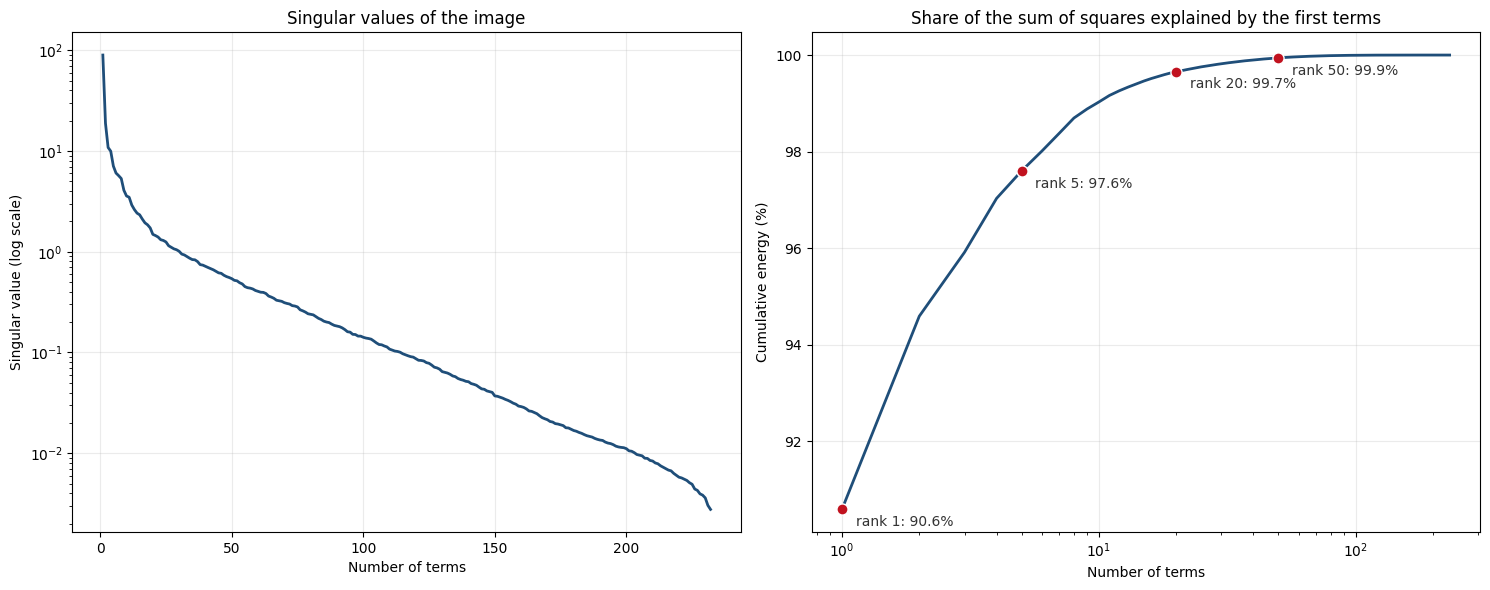

In [5]:
energy = np.cumsum(d**2)/np.sum(d**2)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].plot(range(1, len(d)+1), d, color='#1f4e79', lw=2)
axes[0].set_yscale('log')
axes[0].set_ylabel('Singular value (log scale)')
axes[0].set_title('Singular values of the image')

axes[1].plot(range(1, len(d)+1), 100*energy, color='#1f4e79', lw=2)
for k in [1, 5, 20, 50]:
    axes[1].plot(k, 100*energy[k-1], 'o', color='#c1121f', markersize=8, markeredgecolor='white', markeredgewidth=1)
    axes[1].annotate(f'rank {k}: {100*energy[k-1]:.1f}%', (k, 100*energy[k-1]), xytext=(10, -12),
                     textcoords='offset points', fontsize=10, color='#333333')
axes[1].set_xscale('log')
axes[1].set_ylabel('Cumulative energy (%)')
axes[1].set_title('Share of the sum of squares explained by the first terms')
for ax in axes:
    ax.set_xlabel('Number of terms')
    ax.grid(True, alpha=0.25)
plt.tight_layout()

## Reconstructing the image term by term

The first panel is the original image; the others add one term each, from rank 1 to rank 15.

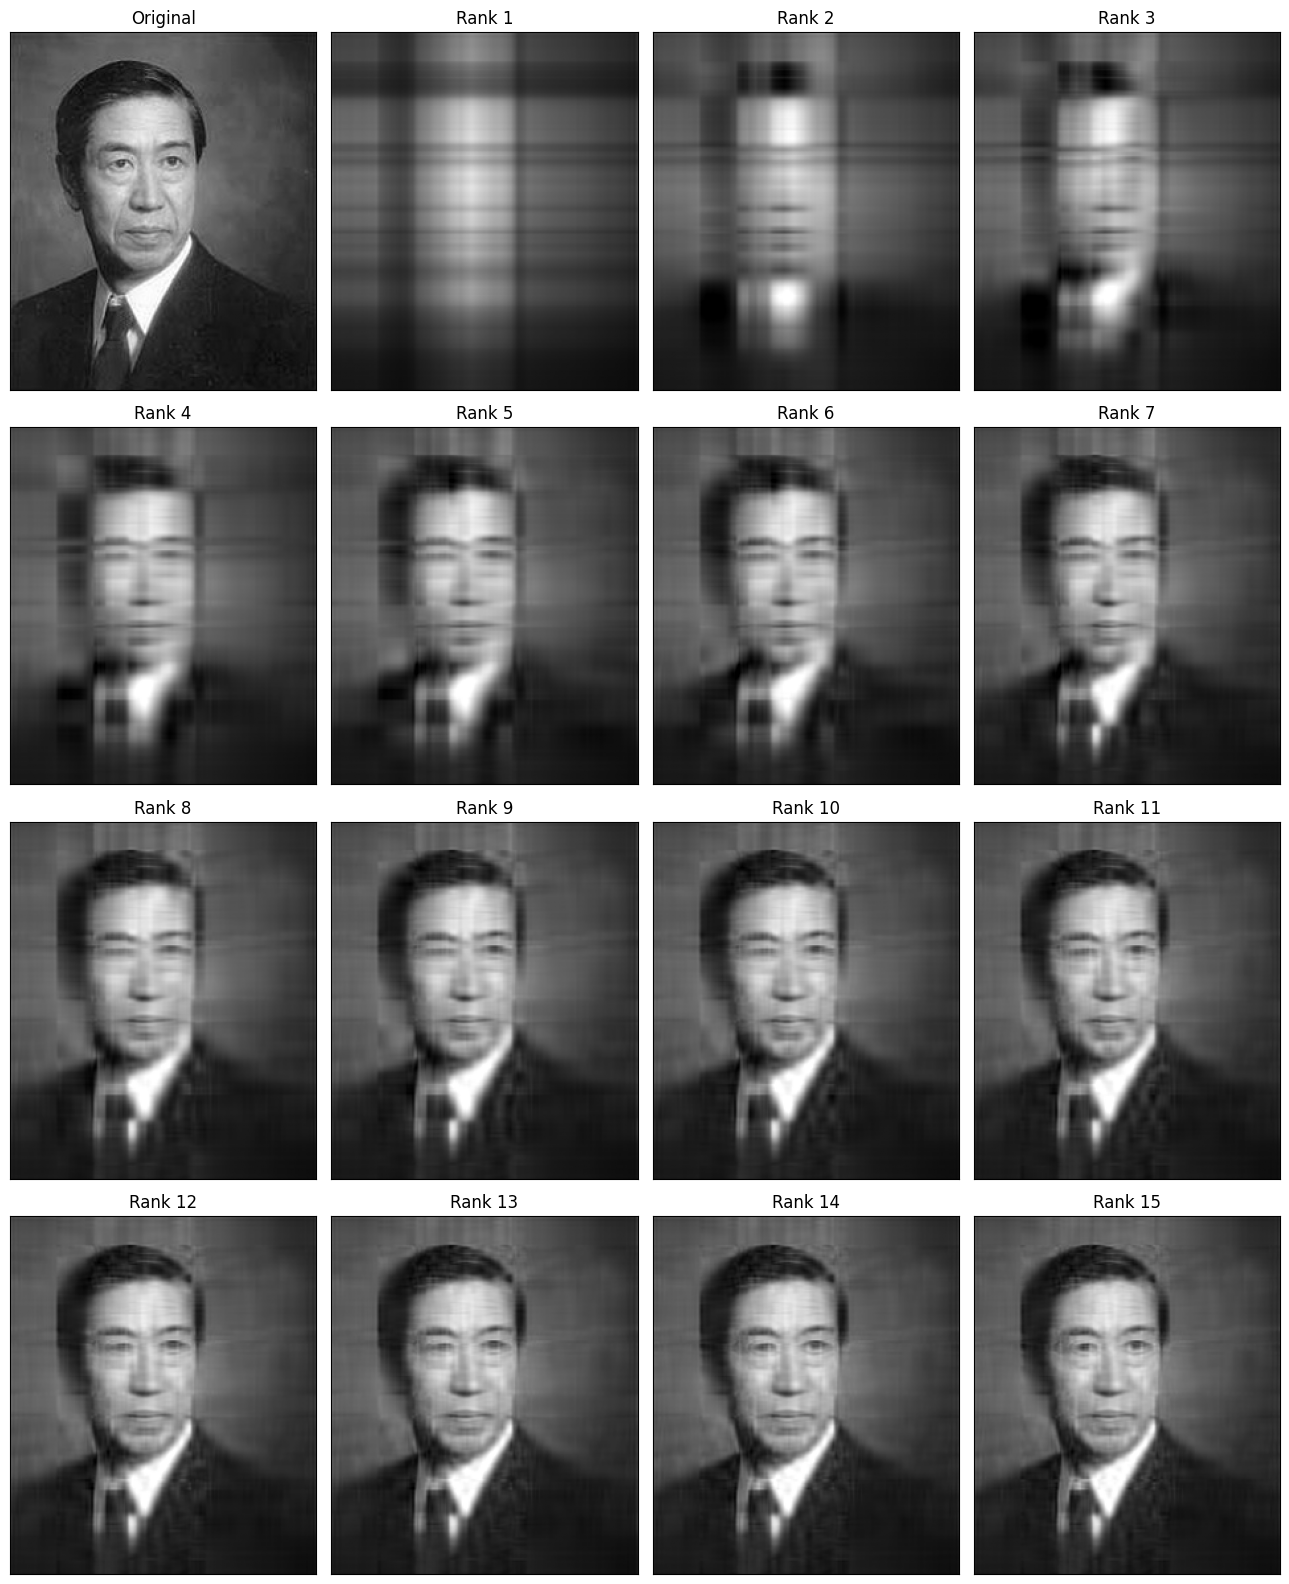

In [6]:
img_svd = np.zeros(n*p).reshape(n,p)
fig, axes = plt.subplots(4, 4, figsize=(13, 16))
for i, ax in enumerate(axes.ravel()):
    if i == 0:
        ax.imshow(img, cmap='gray', vmin=0, vmax=1)
        ax.set_title('Original')
    else:
        img_svd += d[i-1] * u[:,i-1].reshape(n, 1) @ v_T[i-1,:].reshape(1, p)
        ax.imshow(img_svd, cmap='gray', vmin=0, vmax=1)
        ax.set_title(f'Rank {i}')
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()

## Quality against storage

Move the slider to change the rank (this cell needs a running kernel).

In [7]:
def reconstruct(k):
    return (u[:, :k]*d[:k]) @ v_T[:k]

def plot_rank(ax, k):
    storage = 100*k*(n+p+1)/(n*p)
    error = 100*np.sqrt(np.sum((img - reconstruct(k))**2)/np.sum(img**2))
    ax.imshow(reconstruct(k), cmap='gray', vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'Rank {k}\nstorage {storage:.0f}%, error {error:.1f}%')

def interactive_rank(k):
    fig, axes = plt.subplots(1, 2, figsize=(9, 6))
    axes[0].imshow(img, cmap='gray', vmin=0, vmax=1)
    axes[0].set_xticks([])
    axes[0].set_yticks([])
    axes[0].set_title('Original\n')
    plot_rank(axes[1], k)
    plt.show()

interact(interactive_rank, k=IntSlider(value=20, min=1, max=120, description='rank'));

interactive(children=(IntSlider(value=20, description='rank', max=120, min=1), Output()), _dom_classes=('widge…

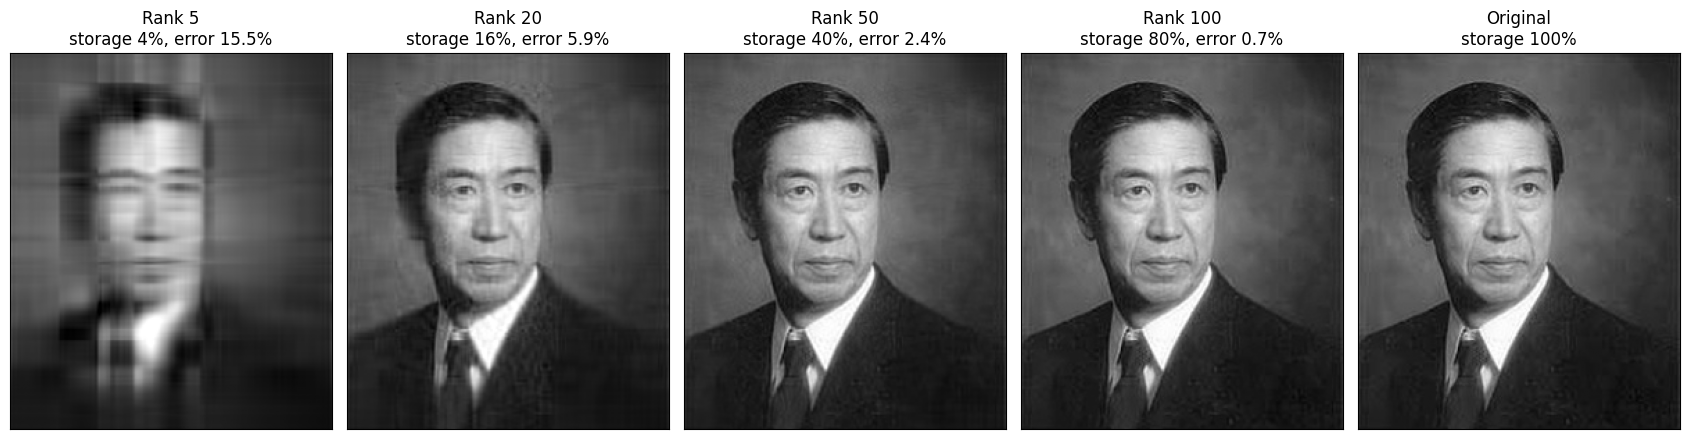

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(17, 5))
for ax, k in zip(axes[:4], [5, 20, 50, 100]):
    plot_rank(ax, k)
axes[4].imshow(img, cmap='gray', vmin=0, vmax=1)
axes[4].set_xticks([])
axes[4].set_yticks([])
axes[4].set_title('Original\nstorage 100%')
plt.tight_layout()

## SVD by blocks

Another way of using the SVD: we cut the image in 100 blocks of 27 x 23 pixels and see each block as one observation with 621 variables. The right singular vectors are then "basis blocks", and each block of the image is a combination of them.

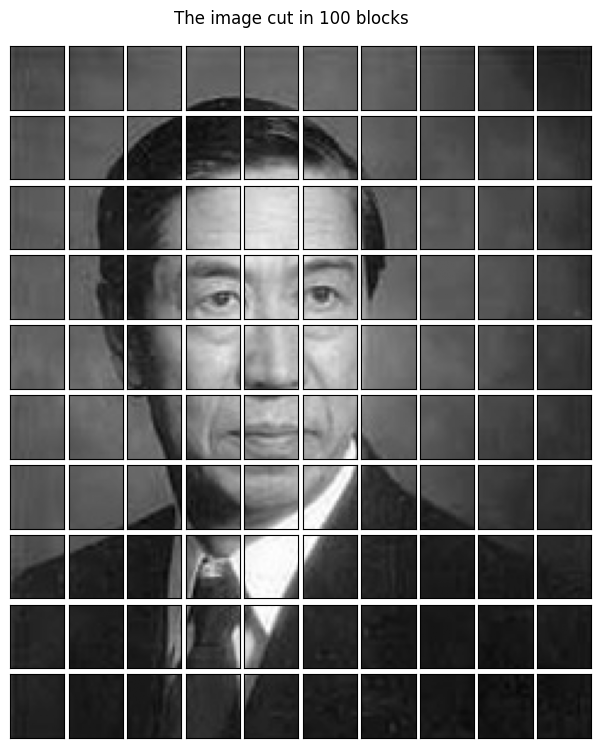

In [9]:
img_block = img[:270,:230]
blocks = img_block.reshape(10,27,10,23).swapaxes(1, 2)

fig, axes = plt.subplots(10, 10, figsize=(7.5, 9))
plt.subplots_adjust(wspace=0.08, hspace=0.08)
for i in range(10):
    for j in range(10):
        axes[i, j].imshow(blocks[i][j], cmap='gray', vmin=0, vmax=1)
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
fig.suptitle('The image cut in 100 blocks', y=0.92);

In [10]:
blocks_flat = blocks.reshape(100,27*23)
n, p = img_block.shape
n_block, p_block =  blocks_flat.shape
u, d, v_T  = np.linalg.svd(blocks_flat, full_matrices=False)

The first right singular vectors, drawn as blocks. The first one is an average block; the next ones are patterns of light and shadow (blue is negative, red is positive).

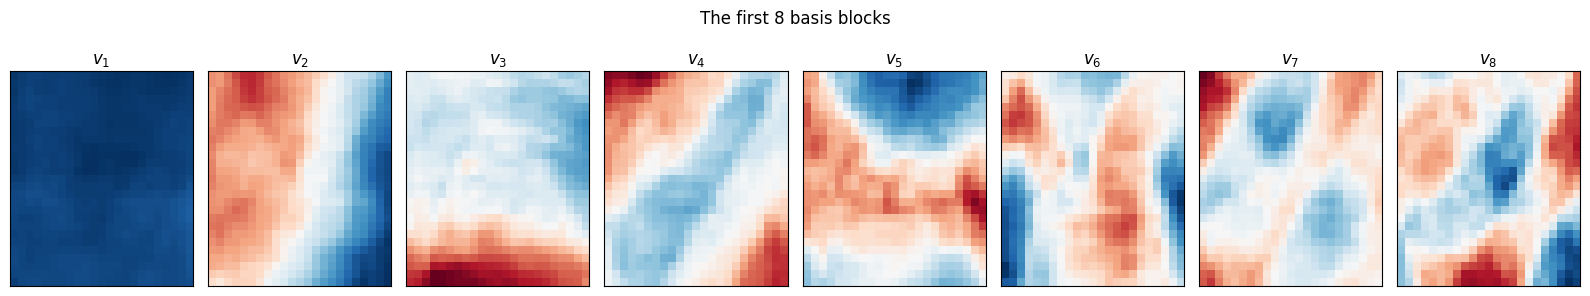

In [11]:
fig, axes = plt.subplots(1, 8, figsize=(16, 3))
for j, ax in enumerate(axes):
    basis = v_T[j].reshape(27, 23)
    limit = np.abs(basis).max()
    ax.imshow(basis, cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'$v_{{{j+1}}}$')
fig.suptitle('The first 8 basis blocks')
fig.tight_layout(rect=(0, 0, 1, 0.94))

Reconstruction of the image adding one basis block at a time, from 1 to 15. Now the approximation improves block by block instead of with horizontal and vertical stripes.

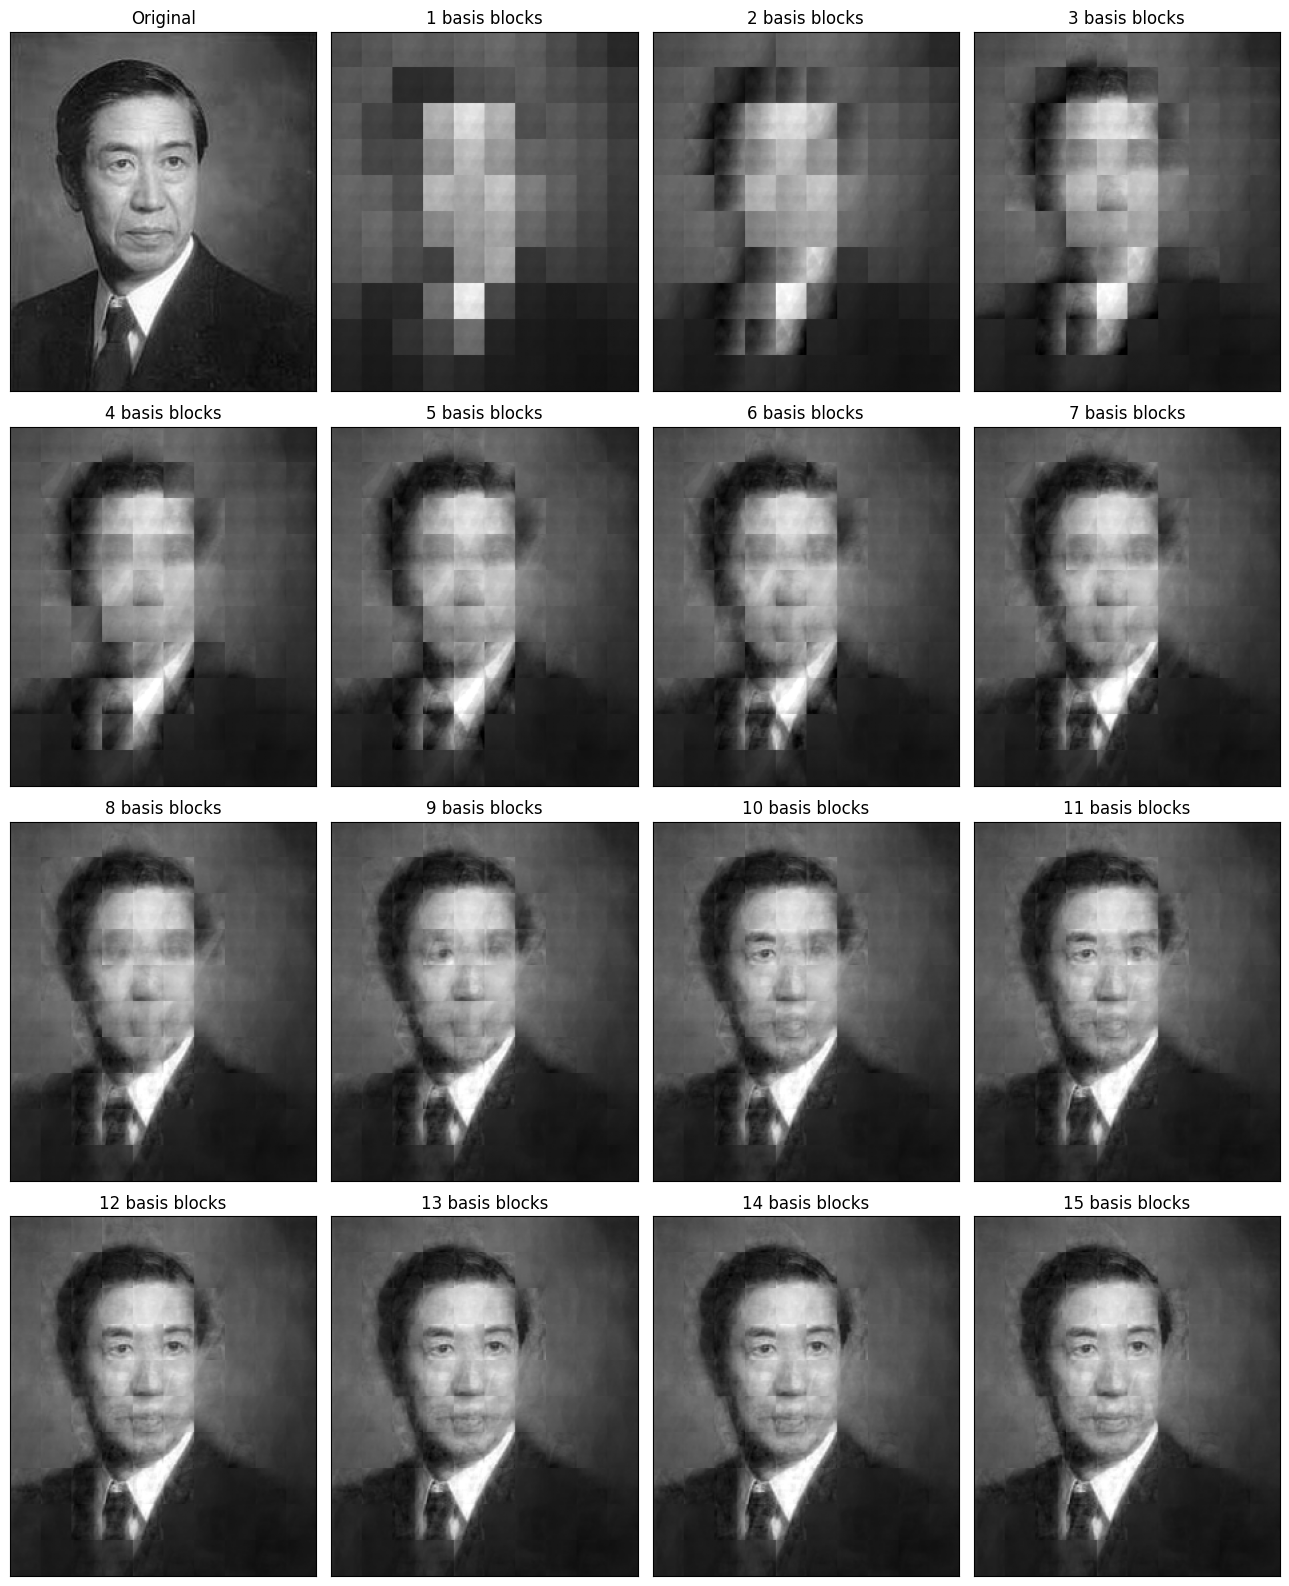

In [12]:
img_svd = np.zeros(n*p).reshape(n,p)
fig, axes = plt.subplots(4, 4, figsize=(13, 16))
for i, ax in enumerate(axes.ravel()):
    if i == 0:
        ax.imshow(img_block, cmap='gray', vmin=0, vmax=1)
        ax.set_title('Original')
    else:
        blocks_flat_recons = d[i-1] * u[:,i-1].reshape(n_block, 1) @ v_T[i-1,:].reshape(1, p_block)
        img_svd += blocks_flat_recons.reshape(10,10,27,23).swapaxes(1,2).reshape(270,230)
        ax.imshow(img_svd, cmap='gray', vmin=0, vmax=1)
        ax.set_title(f'{i} basis blocks')
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()